In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.ml import Pipeline
from pyspark.ml.classification import (LogisticRegression,
                                       RandomForestClassifier,
                                       GBTClassifier)
from pyspark.ml.evaluation import (BinaryClassificationEvaluator,
                                   MulticlassClassificationEvaluator)
from pyspark.ml.feature import (VectorAssembler, StringIndexer,
                                OneHotEncoder, StandardScaler)
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

_jdk = r"C:\Program Files\Microsoft\jdk-17.0.21.21-hotspot"
if "JAVA_HOME" not in os.environ and os.path.isdir(_jdk):
    os.environ["JAVA_HOME"] = _jdk

sns.set_theme(style="whitegrid")

DATA_DIR = os.path.dirname(os.path.abspath("__file__")) if "__file__" in globals() else os.getcwd()
PARQUET_PATH = os.path.join(DATA_DIR, "output", "customer_churn.parquet")

spark = (SparkSession.builder
         .appName("CustomerChurnML")
         .master("local[*]")
         .config("spark.driver.memory", "2g")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print(spark.version)

C:\Users\JAYA SUDHESH\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


4.3.0


In [2]:
df = spark.read.parquet(PARQUET_PATH)
print("Rows:", df.count(), "| Columns:", len(df.columns))
df.printSchema()

LABEL = "churn"
EXCLUDE = {"customer_id", LABEL, "email"}

feature_cols = [c for c in df.columns if c not in EXCLUDE]


from pyspark.sql import functions as F
from pyspark.sql.types import (ByteType, DoubleType, FloatType, IntegerType,
                               LongType, ShortType)
NUMERIC_TYPES = (ByteType, ShortType, IntegerType, LongType,
                 FloatType, DoubleType)
types = {f.name: f.dataType for f in df.schema.fields}
numeric_cols = [c for c in feature_cols
                if isinstance(types[c], NUMERIC_TYPES)]
categorical_cols = [c for c in feature_cols if c not in numeric_cols]
print("Categorical:", categorical_cols)
print("Numeric (%d):" % len(numeric_cols), numeric_cols)

Rows: 221 | Columns: 43
root
 |-- customer_id: long (nullable = true)
 |-- subscription_plan: string (nullable = true)
 |-- delivery_service: string (nullable = true)
 |-- churn: long (nullable = true)
 |-- order_count: long (nullable = true)
 |-- total_spend: long (nullable = true)
 |-- max_order_value: long (nullable = true)
 |-- delivered_order_count: long (nullable = true)
 |-- late_delivery_count: long (nullable = true)
 |-- avg_order_value: double (nullable = true)
 |-- late_delivery_ratio: double (nullable = true)
 |-- items_purchased: long (nullable = true)
 |-- distinct_products: long (nullable = true)
 |-- distinct_categories: long (nullable = true)
 |-- review_count: double (nullable = true)
 |-- avg_star_rating: double (nullable = true)
 |-- negative_review_ratio: double (nullable = true)
 |-- contact_count: double (nullable = true)
 |-- complaint_count: double (nullable = true)
 |-- query_count: double (nullable = true)
 |-- email_contact_count: double (nullable = true)
 |

In [3]:

fill_numeric = {c: 0.0 for c in numeric_cols}
if fill_numeric:
    df = df.fillna(fill_numeric)
for c in categorical_cols:
    df = df.withColumn(c, F.coalesce(F.col(c).cast("string"),
                                     F.lit("unknown")))

cat_indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx",
                              handleInvalid="keep")
                for c in categorical_cols]
encoders = [OneHotEncoder(inputCols=[f"{c}_idx"],
                          outputCols=[f"{c}_ohe"], dropLast=False)
            for c in categorical_cols]

assembler_inputs = numeric_cols + [f"{c}_ohe" for c in categorical_cols]
assembler = VectorAssembler(inputCols=assembler_inputs, outputCol="features_raw")
scaler = StandardScaler(inputCol="features_raw", outputCol="features",
                        withMean=True, withStd=True)

pipeline_stages = cat_indexers + encoders + [assembler, scaler]
preprocess = Pipeline(stages=pipeline_stages)
prepped = preprocess.fit(df).transform(df)
prepped.select("features", LABEL).show(3, truncate=40)

train, test = prepped.randomSplit([0.75, 0.25], seed=42)
print("Train:", train.count(), "Test:", test.count())

+----------------------------------------+-----+
|                                features|churn|
+----------------------------------------+-----+
|[-0.6679975826325169,-0.4730347400761...|    1|
|[1.1647602776880415,0.652357797147965...|    0|
|[1.5659218694320265,0.942012738144765...|    0|
+----------------------------------------+-----+
only showing top 3 rows


Train: 175 Test: 46


In [4]:
evaluator = BinaryClassificationEvaluator(
    labelCol=LABEL, metricName="areaUnderROC")

MODELS = {
    "LogisticRegression": (
        LogisticRegression(featuresCol="features", labelCol=LABEL, maxIter=100),
        ParamGridBuilder()
            .addGrid(LogisticRegression.regParam, [0.01, 0.1, 1.0])
            .addGrid(LogisticRegression.elasticNetParam, [0.0, 0.5])
            .build()),
    "RandomForest": (
        RandomForestClassifier(featuresCol="features", labelCol=LABEL,
                               seed=42),
        ParamGridBuilder()
            .addGrid(RandomForestClassifier.numTrees, [50, 100, 200])
            .addGrid(RandomForestClassifier.maxDepth, [4, 8, 12])
            .addGrid(RandomForestClassifier.minInstancesPerNode, [1, 5])
            .build()),
    "GradientBoosting": (
        GBTClassifier(featuresCol="features", labelCol=LABEL,
                      seed=42, maxIter=50),
        ParamGridBuilder()
            .addGrid(GBTClassifier.maxDepth, [3, 5])
            .addGrid(GBTClassifier.stepSize, [0.05, 0.1, 0.2])
            .addGrid(GBTClassifier.subsamplingRate, [0.8, 1.0])
            .build()),
}

results = {}
for name, (estimator, grid) in MODELS.items():
    cv = CrossValidator(estimator=estimator, estimatorParamMaps=grid,
                        evaluator=evaluator, numFolds=3, seed=42)
    cv_model = cv.fit(train)
    pred = cv_model.transform(test)
    results[name] = (cv_model.bestModel, pred)
    print(f"{name}: best CV AUC = {max(cv_model.avgMetrics):.4f}")


LogisticRegression: best CV AUC = 0.9516


RandomForest: best CV AUC = 0.9693


GradientBoosting: best CV AUC = 0.9588


In [5]:

metrics_rows = []
for name, (model, pred) in results.items():
    acc = MulticlassClassificationEvaluator(labelCol=LABEL,
        metricName="accuracy").evaluate(pred)
    f1 = MulticlassClassificationEvaluator(labelCol=LABEL,
        metricName="f1").evaluate(pred)
    auc = BinaryClassificationEvaluator(labelCol=LABEL,
        metricName="areaUnderROC").evaluate(pred)
    metrics_rows.append({"model": name, "accuracy": round(acc, 4),
                         "f1": round(f1, 4), "auc": round(auc, 4)})
    print(f"{name}: acc={acc:.4f} f1={f1:.4f} auc={auc:.4f}")

metrics_df = pd.DataFrame(metrics_rows).sort_values("auc", ascending=False)
metrics_df

LogisticRegression: acc=0.8913 f1=0.8911 auc=0.9394


RandomForest: acc=0.9783 f1=0.9782 auc=1.0000


GradientBoosting: acc=0.9565 f1=0.9565 auc=1.0000


,model,accuracy,f1,auc
1,RandomForest,0.9783,0.9782,1.0000
2,GradientBoosting,0.9565,0.9565,1.0000
0,LogisticRegression,0.8913,0.8911,0.9394


C:\Users\JAYA SUDHESH\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


C:\Users\JAYA SUDHESH\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


C:\Users\JAYA SUDHESH\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


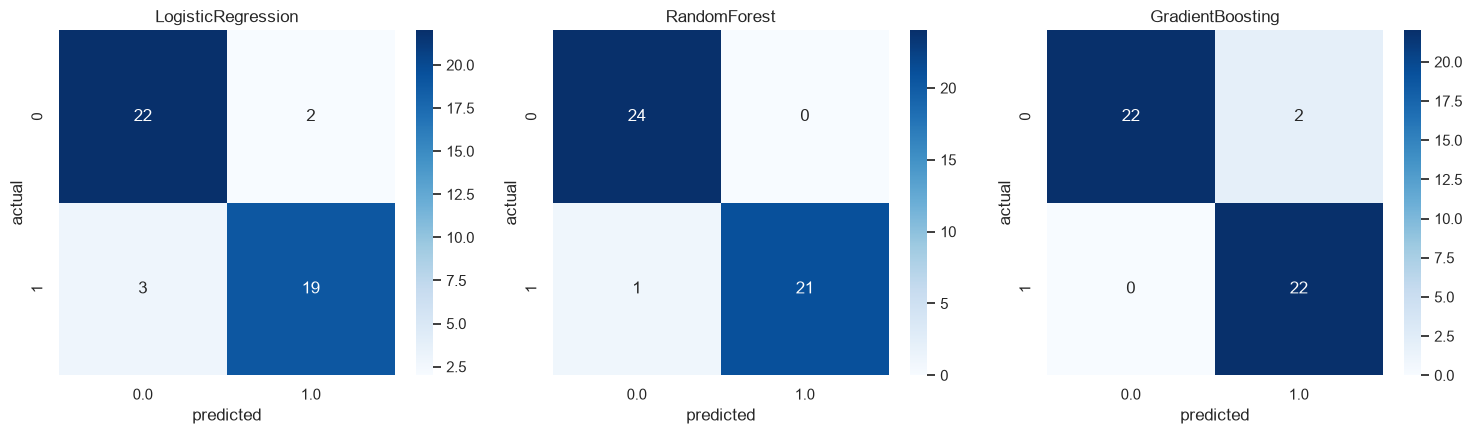

In [6]:
def confusion_matrix_pdf(pred):
    pdf = pred.select(LABEL, "prediction").toPandas()
    cm = pd.crosstab(pdf[LABEL], pdf["prediction"]).astype(int)
    cm.index.name = "actual"
    cm.columns.name = "predicted"
    return cm


fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4.5))
if len(results) == 1:
    axes = [axes]
for ax, (name, (_, pred)) in zip(axes, results.items()):
    cm = confusion_matrix_pdf(pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

C:\Users\JAYA SUDHESH\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


C:\Users\JAYA SUDHESH\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


C:\Users\JAYA SUDHESH\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


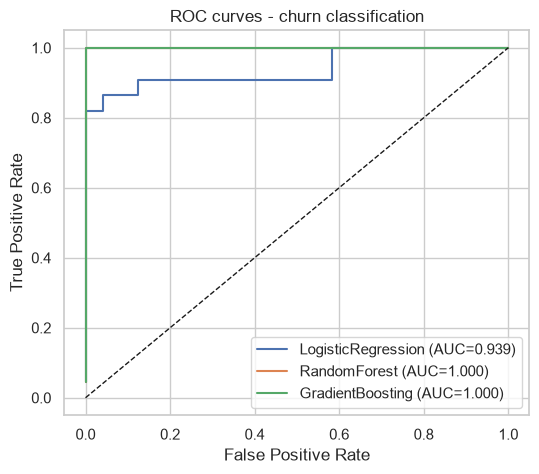

In [7]:
def roc_data(pred):
    pdf = pred.select("probability", LABEL).toPandas()
    probs = np.array([v[1] for v in pdf["probability"]])
    y = pdf[LABEL].to_numpy()
    order = np.argsort(-probs)
    y_sorted = y[order]
    tps = np.cumsum(y_sorted)
    fps = np.cumsum(1 - y_sorted)
    tpr = tps / tps[-1]
    fpr = fps / fps[-1]
    return fpr, tpr


fig, ax = plt.subplots(figsize=(6, 5))
for name, (_, pred) in results.items():
    fpr, tpr = roc_data(pred)
    auc = BinaryClassificationEvaluator(labelCol=LABEL,
        metricName="areaUnderROC").evaluate(pred)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves - churn classification")
ax.legend()
plt.show()

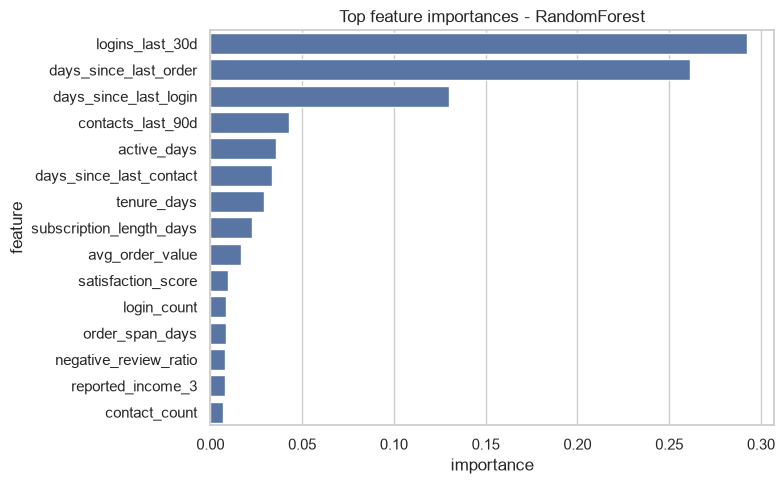

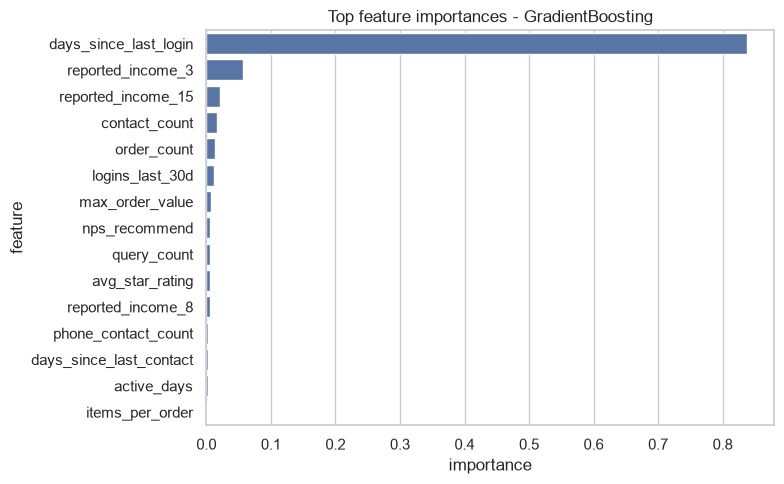

In [8]:

feature_names = list(numeric_cols)
for c in categorical_cols:
    n_cat = df.select(c).distinct().count()
    feature_names += [f"{c}_{i}" for i in range(n_cat + 1)]

for name in ["RandomForest", "GradientBoosting"]:
    if name not in results:
        continue
    model = results[name][0]
    imp = model.featureImportances.toArray()
    imp_df = (pd.DataFrame({"feature": feature_names, "importance": imp})
              .sort_values("importance", ascending=False).head(15))
    plt.figure(figsize=(8, 5))
    sns.barplot(data=imp_df, x="importance", y="feature")
    plt.title(f"Top feature importances - {name}")
    plt.tight_layout()
    plt.show()

In [9]:
best_name = metrics_df.iloc[0]["model"]
best_model, best_pred = results[best_name]
print("Best model:", best_name)
print("Params:", best_model.extractParamMap())
best_pred.select(LABEL, "prediction", "probability").show(10)

spark.stop()

Best model: RandomForest
Params: {Param(parent='RandomForestClassifier_f7e6afba2b7d', name='bootstrap', doc='Whether bootstrap samples are used when building trees.'): True, Param(parent='RandomForestClassifier_f7e6afba2b7d', name='cacheNodeIds', doc='If false, the algorithm will pass trees to executors to match instances with nodes. If true, the algorithm will cache node IDs for each instance. Caching can speed up training of deeper trees. Users can set how often should the cache be checkpointed or disable it by setting checkpointInterval.'): False, Param(parent='RandomForestClassifier_f7e6afba2b7d', name='checkpointInterval', doc='set checkpoint interval (>= 1) or disable checkpoint (-1). E.g. 10 means that the cache will get checkpointed every 10 iterations. Note: this setting will be ignored if the checkpoint directory is not set in the SparkContext.'): 10, Param(parent='RandomForestClassifier_f7e6afba2b7d', name='featureSubsetStrategy', doc="The number of features to consider for 

+-----+----------+--------------------+
|churn|prediction|         probability|
+-----+----------+--------------------+
|    0|       0.0|[0.99555893576017...|
|    1|       1.0|         [0.05,0.95]|
|    1|       1.0|           [0.1,0.9]|
|    0|       0.0|[0.94185523205647...|
|    1|       1.0|         [0.15,0.85]|
|    1|       1.0|         [0.05,0.95]|
|    1|       1.0|[0.02,0.980000000...|
|    1|       1.0|           [0.0,1.0]|
|    0|       0.0|[0.99018856538980...|
|    1|       1.0|           [0.2,0.8]|
+-----+----------+--------------------+
only showing top 10 rows
